<a href="https://colab.research.google.com/github/Arya-006/Youtube-Recommendation-System/blob/main/Youtube_Recommendation_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Install and import libraries


In [1]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


Upload and load your CSV files

In [7]:
videos = pd.read_csv("videos.csv")
interactions = pd.read_csv("interactions.csv")

print("Videos dataset:", videos.shape)
print("Interactions dataset:", interactions.shape)

display(videos.head())
display(interactions.head())

Videos dataset: (30, 7)
Interactions dataset: (600, 5)


,video_id,title,description,category,tags,duration_minutes,video_url
0,V001,Python for Beginners,Learn Python variables loops functions and bas...,Programming,"python, coding, beginner, tutorial",12,https://www.youtube.com/
1,V002,Build Your First Python Project,Create a small Python project and practice fun...,Programming,"python, project, coding, beginner",18,https://www.youtube.com/
2,V003,Python Lists and Dictionaries,Understand lists dictionaries tuples and commo...,Programming,"python, lists, dictionaries, data structures",14,https://www.youtube.com/
3,V004,Pandas Tutorial for Data Analysis,Learn DataFrames filtering grouping and cleani...,Data Science,"pandas, python, data analysis, dataframe",16,https://www.youtube.com/
4,V005,NumPy Basics,Explore arrays indexing vectorized operations ...,Data Science,"numpy, python, arrays, data science",13,https://www.youtube.com/


,user_id,video_id,clicked,watch_time_pct,liked
0,U001,V001,0,0.0,0
1,U001,V002,1,67.4,0
2,U001,V003,1,88.1,1
3,U001,V004,0,0.0,0
4,U001,V005,1,74.0,1


Clean and explore the data

In [8]:
# Remove duplicate records
videos = videos.drop_duplicates(subset="video_id").copy()
interactions = interactions.drop_duplicates(
    subset=["user_id", "video_id"]
).copy()

# Fill missing text
for column in ["title", "description", "category", "tags"]:
    videos[column] = videos[column].fillna("").astype(str)

# Remove interactions linked to unknown videos
videos["video_id"] = videos["video_id"].astype(str)
interactions["video_id"] = interactions["video_id"].astype(str)

interactions = interactions[
    interactions["video_id"].isin(videos["video_id"])
].copy()

print("Missing values in videos:")
display(videos.isnull().sum())

print("Cleaned dataset sizes:")
print("Videos:", len(videos))
print("Interactions:", len(interactions))

Missing values in videos:


,0
video_id,0
title,0
description,0
category,0
tags,0
duration_minutes,0
video_url,0


Cleaned dataset sizes:
Videos: 30
Interactions: 600


Graph 1 — Video categories:

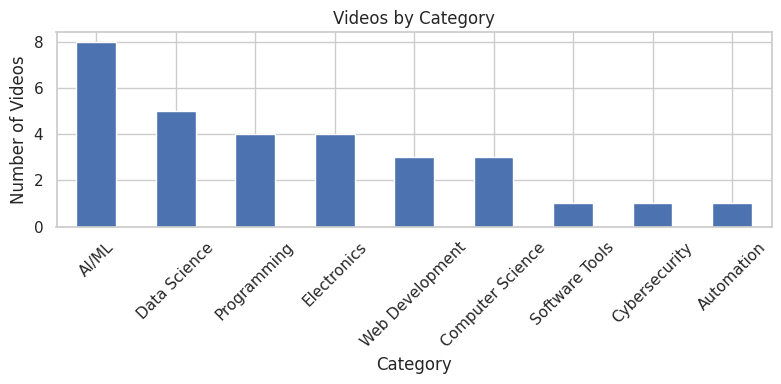

In [9]:
videos["category"].value_counts().plot(
    kind="bar", figsize=(8, 4)
)

plt.title("Videos by Category")
plt.xlabel("Category")
plt.ylabel("Number of Videos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Graph 2 — Most-clicked videos:

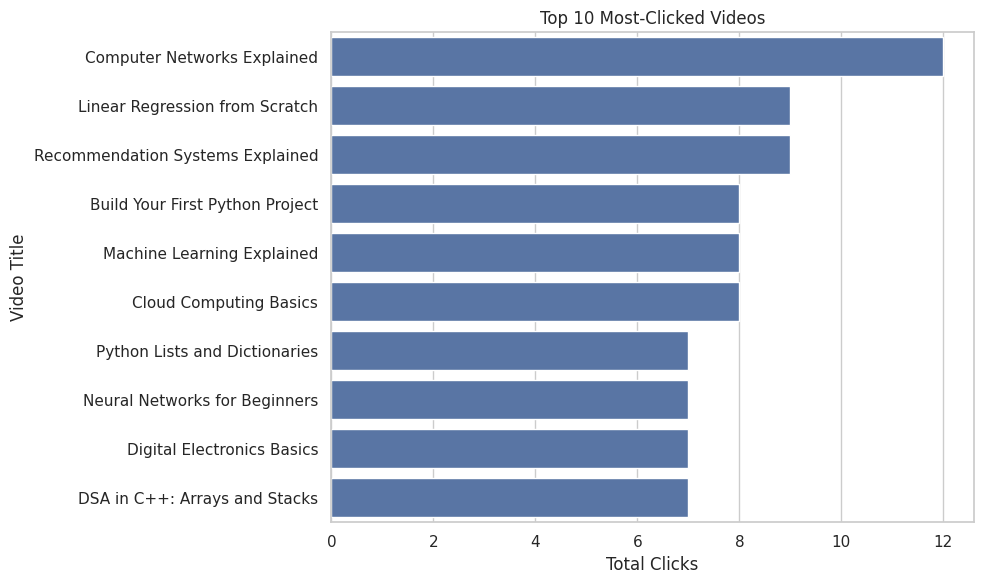

In [10]:
clicks = (
    interactions.groupby("video_id")["clicked"]
    .sum()
    .reset_index(name="total_clicks")
)

top_videos = (
    clicks.merge(
        videos[["video_id", "title"]],
        on="video_id",
        how="left"
    )
    .nlargest(10, "total_clicks")
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_videos,
    x="total_clicks",
    y="title"
)

plt.title("Top 10 Most-Clicked Videos")
plt.xlabel("Total Clicks")
plt.ylabel("Video Title")
plt.tight_layout()
plt.show()

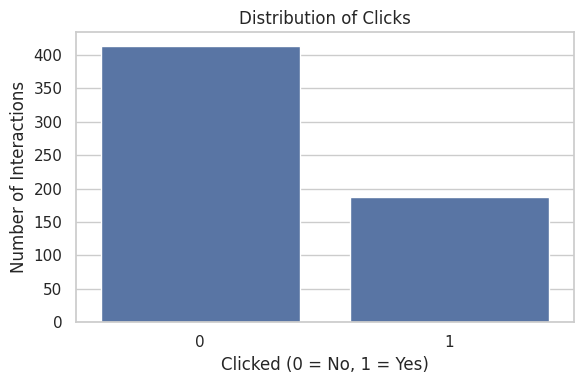

In [6]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=interactions,
    x="clicked"
)

plt.title("Distribution of Clicks")
plt.xlabel("Clicked (0 = No, 1 = Yes)")
plt.ylabel("Number of Interactions")
plt.tight_layout()
plt.show()

Build the similar-video recommendation model

In [11]:
videos["combined_text"] = (
    videos["title"] + " " +
    videos["description"] + " " +
    videos["category"] + " " +
    videos["tags"]
)

tfidf = TfidfVectorizer(stop_words="english")

tfidf_matrix = tfidf.fit_transform(videos["combined_text"])

similarity_matrix = cosine_similarity(tfidf_matrix)

print("TF-IDF features:", tfidf_matrix.shape)
print("Similarity matrix:", similarity_matrix.shape)
print("Recommendation model ready!")

TF-IDF features: (30, 220)
Similarity matrix: (30, 30)
Recommendation model ready!


Recommend similar videos

In [12]:
def recommend_similar(video_title, number=5):

    matches = videos[
        videos["title"].str.contains(
            video_title, case=False, regex=False, na=False
        )
    ]

    if matches.empty:
        print("Video not found. Try another title.")
        return

    selected_index = matches.index[0]

    scores = similarity_matrix[selected_index].copy()

    # Exclude the selected video
    scores[selected_index] = -1

    recommended_indices = np.argsort(scores)[::-1][:number]

    results = videos.iloc[recommended_indices][
        ["video_id", "title", "category"]
    ].copy()

    results["similarity_score"] = scores[recommended_indices]

    print("Selected video:", videos.loc[selected_index, "title"])

    return results.reset_index(drop=True)

In [13]:
# View titles available in your dataset
display(videos[["title", "category"]])

# Recommend videos similar to the first video
recommend_similar(videos.iloc[0]["title"], number=5)

,title,category
0,Python for Beginners,Programming
1,Build Your First Python Project,Programming
2,Python Lists and Dictionaries,Programming
3,Pandas Tutorial for Data Analysis,Data Science
4,NumPy Basics,Data Science
5,Machine Learning Explained,AI/ML
6,Linear Regression from Scratch,AI/ML
7,Logistic Regression Tutorial,AI/ML
8,KNN Algorithm Visualized,AI/ML
9,Recommendation Systems Explained,AI/ML


Selected video: Python for Beginners


,video_id,title,category,similarity_score
0,V002,Build Your First Python Project,Programming,0.395090
1,V003,Python Lists and Dictionaries,Programming,0.210641
2,V018,JavaScript for Beginners,Web Development,0.164212
3,V011,Build a Movie Recommendation System,AI/ML,0.140754
4,V023,Data Visualization with Matplotlib,Data Science,0.112808


Simple personalized recommendations

In [14]:
def recommend_for_user(user_id, number=5):

    user_history = interactions[
        (interactions["user_id"].astype(str) == str(user_id)) &
        (interactions["clicked"] == 1)
    ]

    if user_history.empty:
        print("No clicked-video history found for this user.")
        return

    # Find the categories of videos the user clicked
    watched = videos[
        videos["video_id"].isin(user_history["video_id"])
    ]

    preferred_categories = watched["category"].value_counts()

    # Recommend videos from the user's preferred categories
    watched_ids = set(user_history["video_id"])

    candidates = videos[
        (~videos["video_id"].isin(watched_ids)) &
        (videos["category"].isin(preferred_categories.index))
    ].copy()

    if candidates.empty:
        print("No new videos found in the preferred categories.")
        return

    # Prefer the categories the user clicked most often
    candidates["category_preference"] = candidates["category"].map(
        preferred_categories
    )

    candidates = candidates.sort_values(
        "category_preference", ascending=False
    )

    return candidates[
        ["video_id", "title", "category"]
    ].head(number).reset_index(drop=True)

In [15]:
# View available user IDs
print("Available users:")
print(sorted(interactions["user_id"].astype(str).unique()))

# Try the first available user
example_user = interactions["user_id"].astype(str).iloc[0]

print("Recommendations for user:", example_user)

recommend_for_user(example_user, number=5)

Available users:
['U001', 'U002', 'U003', 'U004', 'U005', 'U006', 'U007', 'U008', 'U009', 'U010', 'U011', 'U012', 'U013', 'U014', 'U015', 'U016', 'U017', 'U018', 'U019', 'U020']
Recommendations for user: U001


,video_id,title,category
0,V028,Generative AI and LLMs,AI/ML
1,V011,Build a Movie Recommendation System,AI/ML
2,V023,Data Visualization with Matplotlib,Data Science
3,V004,Pandas Tutorial for Data Analysis,Data Science
4,V001,Python for Beginners,Programming
